# Building a Health-Domain Language Model — GPU (Colab / Linux)

**ICS554 Natural Language Processing · Prosit 1, Section C · Ashesi University**

We adapt an open, general-purpose language model to the **health domain** in two stages, then
measure whether it actually improved. This notebook runs on any CUDA GPU — a free Colab T4 is
enough.

> **In plain words.** A language model has learned, from an enormous amount of text, which
> words tend to follow which. Ours starts out a generalist. We make it read a lot of *health*
> writing (medical papers, patient-information pages, Ghana's national treatment guidelines),
> then have it *practise answering* health questions. Finally we test it on material it has
> never seen and compare it against the untouched original.

---

## The six questions this notebook answers

| Step | Prosit question | What happens here |
|:--|:--|:--|
| **0** | — | Setup: install, detect the GPU, load the data, set the knobs |
| **1** | Q1 · Data | Inventory exactly what we train and test on |
| **2** | Q2 · Approaches | The options we had, and why we chose this one |
| **3** | Q3 · Training | Stage 1 (read health text) → Stage 2 (practise answering) |
| **4** | Q4 · Evaluation | Base vs +Stage 1 vs +Stage 1+2, on data none of them has seen |
| **5** | Q5 · Results | Tables, charts, and the numbers for your write-up |
| **6** | Q6 · Caveats | What you must know before trusting any of this |

Each step ends with a **Draft answer** box — scaffolding to rewrite in your own words, because
the viva tests whether *you* understand the work.

---

## Design decisions, up front

**Model: `Qwen/Qwen3-4B-Base`.**

- **Text-only.** Qwen3 is the last pure-text Qwen generation. Its successor, Qwen3.5, is
  natively multimodal: the checkpoint carries a vision tower that breaks LoRA training, and
  its tokenizer is a multimodal processor that tries to fetch URLs found in text as images.
  A text-only model deletes a whole class of bugs from a task that has no images in it.
- **Base, not Instruct.** A base model has only been pre-trained — it continues text but does
  not reliably follow instructions. Starting there means every bit of instruction-following we
  measure came from **our** Stage 2, which is what makes the comparison honest.
- **4B fits now.** An earlier attempt at 4B ran out of memory on a T4, but only because the
  multimodal checkpoint forced 32-bit weights. In 4-bit, `Qwen3-4B-Base` is ≈2.5 GB of
  weights and fits a 16 GB card comfortably.

**Method: QLoRA** — the base weights are frozen and quantised to 4 bits, and we train small
low-rank adapters on top. Cheap, reversible, and the original model stays perfectly intact,
which is why *Model A is exactly recoverable* by simply not loading an adapter.

**Training loop: written out by hand.** We deliberately do not use `transformers.Trainer`.
The loop is about forty lines, it does not break when the library's callback internals change,
and you can explain every line of it in the viva.

> ⚠️ **This is a study exercise, not a medical device.** No clinician has validated any output.
> Never use it for a real clinical decision.

---

# Step 0 · Setup

Install, check the GPU, point at the data, set the knobs.

### 0.1 · Install

Pinned to majors that work together. If Colab asks you to restart the runtime after this,
do it, then carry on from the next cell (you do **not** need to re-run this one).

In [7]:
%pip install -q -U "transformers>=4.51" "peft>=0.11" "bitsandbytes>=0.43" accelerate safetensors
# Colab ships torchao 0.10, but recent PEFT requires >0.16 and its is_torchao_available()
# *raises* instead of returning False. PEFT tries a chain of LoRA dispatchers (bitsandbytes,
# torchao, plain Linear) and the torchao one is reached for ordinary fp16 Linear layers, so
# the stale version breaks get_peft_model. Nothing here uses torchao, so remove it.
%pip uninstall -q -y torchao

### 0.2 · Imports and GPU check

The cell below prints what card you actually got. Two things matter:

- **VRAM** — decides the batch size and whether 4B is comfortable.
- **Native bf16** — and note *how* we test for it. `torch.cuda.is_bf16_supported()` is the
  obvious call and it is **misleading here**: it defaults to `including_emulation=True`, so on
  a **T4 it returns `True`** even though Turing (sm_75) has no bf16 tensor cores at all. Using
  bf16 there silently bypasses the tensor cores and runs several times slower. We therefore
  test the **compute capability** instead — bf16 is native from Ampere (sm_80) onward — and
  fall back to fp16 plus a `GradScaler`, which is exactly what a T4's tensor cores are good at.

This is the single most important hardware fact for this notebook.

In [8]:
import gc
import json
import math
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import torch

IN_COLAB = "google.colab" in sys.modules

if not torch.cuda.is_available():
    raise SystemExit(
        "No CUDA GPU visible.\n"
        "In Colab: Runtime -> Change runtime type -> T4 GPU, then run this cell again."
    )

GPU_NAME = torch.cuda.get_device_name(0)
VRAM_GB = torch.cuda.get_device_properties(0).total_memory / 1e9
CC_MAJOR, CC_MINOR = torch.cuda.get_device_capability(0)

# Do NOT use torch.cuda.is_bf16_supported(): it counts *emulated* bf16 and returns True on a
# T4, which has no bf16 tensor cores. Native bf16 starts at Ampere (sm_80).
NATIVE_BF16 = CC_MAJOR >= 8
COMPUTE_DTYPE = torch.bfloat16 if NATIVE_BF16 else torch.float16
USE_GRAD_SCALER = COMPUTE_DTYPE == torch.float16

print(f"GPU                : {GPU_NAME}")
print(f"VRAM               : {VRAM_GB:.1f} GB")
print(f"compute capability : sm_{CC_MAJOR}{CC_MINOR}")
print(f"native bf16        : {NATIVE_BF16}"
      f"{'' if NATIVE_BF16 else '   (Turing/Volta: fp16 tensor cores only)'}")
print(f"compute dtype      : {str(COMPUTE_DTYPE).replace('torch.', '')}"
      f"{'  + GradScaler' if USE_GRAD_SCALER else ''}")
print(f"torch              : {torch.__version__}")
print(f"environment        : {'Colab' if IN_COLAB else 'local / server'}")

if torch.cuda.is_bf16_supported() and not NATIVE_BF16:
    print("\nnote: torch.cuda.is_bf16_supported() reports True on this card, but that "
          "includes emulation.\n      Using fp16 instead, which this GPU accelerates in hardware.")

GPU                : Tesla T4
VRAM               : 15.6 GB
compute capability : sm_75
native bf16        : False   (Turing/Volta: fp16 tensor cores only)
compute dtype      : float16  + GradScaler
torch              : 2.11.0+cu128
environment        : Colab

note: torch.cuda.is_bf16_supported() reports True on this card, but that includes emulation.
      Using fp16 instead, which this GPU accelerates in hardware.


### 0.3 · Find the data (and `hl_lib.py`)

This notebook needs the prepared dataset built by `collect.py` → `prep.py`, which ships as
`colab_health_bundle.zip` (about 40 MB). It contains six `.jsonl` files plus `hl_lib.py`, the
shared helper module.

**On Colab:** put the zip in Google Drive under `MyDrive/health-llm/` (or edit `DRIVE_DIR`
below) and this cell will mount Drive and unpack it.
**On your own Linux box:** just run the notebook from the repository, or drop the zip beside it.

> ⚠️ If you ran an earlier version of this project, **re-upload the bundle**. Older bundles were
> built before the Ghana Standard Treatment Guidelines download was fixed, and contain no
> Ghana text at all — no Ghana training data and no Ghana row in the perplexity table.

In [9]:
DRIVE_DIR = "/content/drive/MyDrive/NLP_LABS/health_llm"   # where the zip lives, and where results are saved
WORK = Path("/content/health-llm") if IN_COLAB else Path.cwd()

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

BASE = Path(DRIVE_DIR) if IN_COLAB else WORK      # checkpoints and results are written here
BASE.mkdir(parents=True, exist_ok=True)
WORK.mkdir(parents=True, exist_ok=True)
os.chdir(WORK)

# Unpack the bundle if the data is not already here
REQUIRED = ["cpt_train.jsonl", "ppl_heldout.jsonl", "sft_train.jsonl",
            "sft_val.jsonl", "mcq_eval.jsonl", "vignettes.jsonl"]

def _find_data():
    """Return the directory holding the prepared jsonl files, or None."""
    for d in (WORK, WORK / "data" / "prep", Path.cwd() / "data" / "prep", Path(DRIVE_DIR)):
        if all((d / f).exists() for f in REQUIRED):
            return d
    return None

DATA = _find_data()

if DATA is None:
    import zipfile
    zips = [Path(DRIVE_DIR) / "colab_health_bundle.zip", WORK / "colab_health_bundle.zip"]
    src = next((z for z in zips if z.exists()), None)
    if src is None:
        raise FileNotFoundError(
            "Could not find the prepared data or colab_health_bundle.zip.\n"
            f"Looked in: {[str(z) for z in zips]}\n\n"
            "Build it from the repository root with:\n"
            "    python collect.py medlineplus && python collect.py moh\n"
            "    python collect.py hf && python collect.py pmc 3000\n"
            "    python prep.py\n"
            f"then upload colab_health_bundle.zip to {DRIVE_DIR}/."
        )
    print(f"unpacking {src}")
    zipfile.ZipFile(src).extractall(WORK)
    DATA = _find_data()
    if DATA is None:
        raise FileNotFoundError(f"{src} did not contain all of {REQUIRED}")

sys.path.insert(0, str(DATA))
sys.path.insert(0, str(WORK))
import hl_lib   # SYSTEM prompt, chatml(), packing, perplexity, MCQ scoring, generation

print(f"data   : {DATA}")
print(f"results: {BASE}")
print(f"hl_lib : {hl_lib.__file__}")

Mounted at /content/drive
unpacking /content/drive/MyDrive/NLP_LABS/health_llm/colab_health_bundle.zip
data   : /content/health-llm
results: /content/drive/MyDrive/NLP_LABS/health_llm
hl_lib : /content/health-llm/hl_lib.py


### 0.4 · Configuration — every knob in one place

**On the LoRA settings.** These are Hugging Face PEFT's names, and they match the report
directly: `r=32`, `lora_alpha=64`, on all seven projections of every transformer block.

**On the batch size.** `MICRO_BATCH × GRAD_ACCUM = 16` blocks per optimiser update — 32,768
tokens, the same effective batch the project has used throughout. Raise `MICRO_BATCH` if you
have a bigger card; the product is what matters for comparability.

**On the budget.** `TOKEN_BUDGET` is the single biggest lever on run time. 3 M tokens is the
documented default. The training cell prints a measured throughput and an ETA after the first
few steps, so you can stop and lower it if it is going to take too long.

In [10]:
# ── Model ─────────────────────────────────────────────────────────────────────
MODEL = "Qwen/Qwen3-4B-Base"     # text-only, base (not instruct)
# 4-bit (QLoRA) saves memory but costs speed: every matmul dequantises first, and
# bitsandbytes' NF4 kernels are tuned for Ampere, so they are slow on a Turing T4. This model
# is ~8.2 GB in fp16, which fits a 16 GB card, so we keep the weights in 16 bit and spend the
# memory instead of the time. Set True if you OOM on load.
LOAD_IN_4BIT = False

# ── LoRA adapter (HF PEFT names; matches the report's r=32 / alpha=64) ────────
LORA_R, LORA_ALPHA, LORA_DROPOUT = 32, 64, 0.0
LORA_TARGETS = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]

# ── Stage 1: continued pre-training ───────────────────────────────────────────
BLOCK = 2048                 # tokens per packed training block
TOKEN_BUDGET = 3_000_000     # how much health text Stage 1 reads. Biggest lever on run time.
CPT_LR = 1e-4
N_VAL_BLOCKS = 40            # blocks held back from training to watch for over-fitting

# ── Stage 2: instruction tuning ───────────────────────────────────────────────
# 6,000 examples is 375 optimiser steps, which measured out at roughly 4-5 hours on a T4 —
# longer than a Colab session survives. 3,000 halves it, and is the count the Apple Silicon
# run used, where Stage 2 produced the strongest signal in the project.
MAX_SFT = 3000               # Q&A examples to train on
SFT_MAX_LEN = 1536           # tokens per example
SFT_LR = 1e-4
N_VAL_SFT = 100

# ── Shared training settings ──────────────────────────────────────────────────
MICRO_BATCH = 1
GRAD_ACCUM = 16              # MICRO_BATCH x GRAD_ACCUM = 16 blocks = 32,768 tokens per update
# Gradient checkpointing recomputes activations instead of storing them: ~30-40% slower, but
# required here. Storing activations for 36 layers at 2048 tokens needs roughly 7 GB, which
# does not fit alongside 16-bit weights. Measured, not guessed: turning this off OOMs.
GRAD_CHECKPOINT = True
SAVE_EVERY = 10              # optimiser steps between adapter checkpoints (Colab disconnects)
WARMUP_STEPS = 10
WEIGHT_DECAY = 0.01
MAX_GRAD_NORM = 1.0
LOG_EVERY = 5                # optimiser steps between loss reports
EVAL_EVERY = 25              # optimiser steps between validation passes
SEED = 3407

# ── Evaluation ────────────────────────────────────────────────────────────────
N_MCQ = 300                  # exam questions per task (500 available). Lower = faster.
PPL_MAX_LEN = 1024           # tokens scored per held-out passage
N_VIGNETTES = 12

# ── Where things are written ──────────────────────────────────────────────────
ADAPTER_CPT = BASE / "adapter_cpt"
ADAPTER_SFT = BASE / "adapter_sft"
RESULTS = BASE / "results"
for d in (ADAPTER_CPT, ADAPTER_SFT, RESULTS):
    d.mkdir(parents=True, exist_ok=True)

torch.manual_seed(SEED)

print(f"model           : {MODEL}  ({'4-bit QLoRA' if LOAD_IN_4BIT else '16-bit LoRA'})")
print(f"LoRA            : r={LORA_R}, alpha={LORA_ALPHA} on {len(LORA_TARGETS)} projections, all layers")
print(f"effective batch : {MICRO_BATCH * GRAD_ACCUM} blocks = "
      f"{MICRO_BATCH * GRAD_ACCUM * BLOCK:,} tokens per optimiser step")
print(f"stage 1 budget  : {TOKEN_BUDGET/1e6:.1f} M tokens "
      f"(~{TOKEN_BUDGET // (MICRO_BATCH * GRAD_ACCUM * BLOCK)} optimiser steps)")
print(f"stage 2         : {MAX_SFT:,} examples "
      f"(~{MAX_SFT // (MICRO_BATCH * GRAD_ACCUM)} optimiser steps)")
print(f"grad checkpoint : {GRAD_CHECKPOINT}"
      f"{'  (needed: activations alone are ~7 GB here)' if GRAD_CHECKPOINT else ''}")
print(f"checkpointing   : adapter saved every {SAVE_EVERY} steps")
print(f"writing to      : {BASE}")

model           : Qwen/Qwen3-4B-Base  (16-bit LoRA)
LoRA            : r=32, alpha=64 on 7 projections, all layers
effective batch : 16 blocks = 32,768 tokens per optimiser step
stage 1 budget  : 3.0 M tokens (~91 optimiser steps)
stage 2         : 3,000 examples (~187 optimiser steps)
grad checkpoint : True  (needed: activations alone are ~7 GB here)
checkpointing   : adapter saved every 10 steps
writing to      : /content/drive/MyDrive/NLP_LABS/health_llm


---

# Step 1 · Q1. What data did we use?

> **In plain words.** Three kinds of text. **(1) Reading material** for Stage 1: medical
> research papers, patient-friendly health guides, and Ghana's official treatment guidelines.
> **(2) Practice questions and answers** for Stage 2. **(3) Exam papers we hide from the
> model** so we can test it fairly. The hidden material was separated *before* any training
> started, so the model cannot have memorised the test.

### The sources

**Stage 1 — continued pre-training** (raw text, ≈16 M words)

| Source | What it is | Licence |
|:--|:--|:--|
| PubMed Central Open Access | Full-text clinical research articles | Per article: CC BY, CC0, CC BY-NC, CC BY-NC-SA (no-derivatives excluded) |
| MedlinePlus health topics | Plain-language descriptions of conditions | Public domain (US National Library of Medicine) |
| Ghana Standard Treatment Guidelines + Essential Medicines List (2017) | National clinical guidance | Ghana Ministry of Health; repeated ×3 — it is small but it is our local-context source |

**Stage 2 — instruction tuning.** medical-o1-reasoning-SFT, MedText, MedQuAD, and the
**train** splits of MedMCQA and MedQA, all rendered in one fixed ChatML format with a GP-style
system prompt.

**Held out — never trained on.** Documents from each Stage 1 source, the MedQA **test** split,
the MedMCQA **validation** split, PubMedQA, 22 GP vignettes, and **WikiText-2** as a
general-English *forgetting control*.

**Deliberately excluded.** Scraped patient–doctor chat sets (unclear rights, possible personal
data), StatPearls (CC BY-NC-**ND** — no derivatives conflicts with fine-tuning), copyrighted
exam textbooks.

> **Why "split before training" matters.** If test text leaks into training, the model can look
> better simply by having memorised it. Splitting first is what makes the comparison mean
> anything.

In [11]:
import collections

cpt_docs  = hl_lib.load_jsonl(DATA / "cpt_train.jsonl")
heldout   = hl_lib.load_jsonl(DATA / "ppl_heldout.jsonl")
sft_train = hl_lib.load_jsonl(DATA / "sft_train.jsonl")
sft_val   = hl_lib.load_jsonl(DATA / "sft_val.jsonl")
mcq_all   = hl_lib.load_jsonl(DATA / "mcq_eval.jsonl")
vignettes = hl_lib.load_jsonl(DATA / "vignettes.jsonl")

words = collections.Counter()
docs = collections.Counter()
for d in cpt_docs:
    docs[d["source"]] += 1
    words[d["source"]] += len(d["text"].split())

print("STAGE 1 — reading material (continued pre-training)")
print(f"  {'source':<16}{'docs':>8}{'words':>14}")
for source, n in docs.most_common():
    print(f"  {source:<16}{n:>8,}{words[source]:>14,}")
print(f"  {'TOTAL':<16}{sum(docs.values()):>8,}{sum(words.values()):>14,}")

print(f"\nSTAGE 2 — practice Q&A (instruction tuning)")
print(f"  {len(sft_train):,} training examples + {len(sft_val):,} validation examples")

print("\nHELD OUT — never trained on")
for source, n in collections.Counter(d["source"] for d in heldout).most_common():
    tag = "general-English control" if source == "wikitext2" else "health text"
    print(f"  perplexity, {source:<14}{n:>5} passages   ({tag})")
for task, n in collections.Counter(x["task"] for x in mcq_all).most_common():
    print(f"  exam questions, {task:<11}{n:>5}")
print(f"  GP vignettes {'':<14}{len(vignettes):>5}")

# The Ghana guidelines are the local-context source; their absence is easy to miss.
if not any(d["source"] == "moh_ghana" for d in heldout):
    print("\n  *** WARNING: no Ghana text found. Your bundle predates the STG download fix. ***")

STAGE 1 — reading material (continued pre-training)
  source              docs         words
  pmc_oa             2,850    15,363,776
  moh_ghana          1,128       450,528
  medlineplus          913       315,006
  TOTAL              4,891    16,129,310

STAGE 2 — practice Q&A (instruction tuning)
  9,000 training examples + 300 validation examples

HELD OUT — never trained on
  perplexity, pmc_oa          150 passages   (health text)
  perplexity, wikitext2       150 passages   (general-English control)
  perplexity, medlineplus     102 passages   (health text)
  perplexity, moh_ghana        42 passages   (health text)
  exam questions, MedQA        500
  exam questions, MedMCQA      500
  exam questions, PubMedQA     500
  GP vignettes                  22


Now look at one Stage 2 example in full — the exact format the model is trained on and
evaluated with.

In [12]:
print("ROLES:", " -> ".join(m["role"] for m in sft_train[0]["messages"]))
print("=" * 79)
print(hl_lib.chatml(sft_train[0]["messages"])[:1200])

ROLES: system -> user -> assistant
<|im_start|>system
You are a helpful medical assistant acting like a general practitioner (GP). Given a patient's symptoms or a health question, give the most likely explanations, key questions to ask, sensible next steps, and warning signs that need urgent care. You provide general health information, not a substitute for a clinician.<|im_end|>
<|im_start|>user
Do you have information about Nutrition<|im_end|>
<|im_start|>assistant
Summary : Food provides the energy and nutrients you need to be healthy. Nutrients include proteins, carbohydrates, fats, vitamins, minerals, and water.     Healthy eating is not hard. The key is to       -  Eat a variety of foods, including vegetables, fruits, and whole-grain products    -  Eat lean meats, poultry, fish, beans, and low-fat dairy products     -  Drink lots of water    -  Limit salt, sugar, alcohol, saturated fat, and trans fat in your diet       Saturated fats are usually fats that come from animals. Look 

> **Draft answer (Q1 — 1 paragraph).** We adapted `Qwen3-4B-Base` using open health text in two
> stages. Stage 1 used roughly 16 million words: PubMed Central open-access articles,
> MedlinePlus health topics, and the Ghana Standard Treatment Guidelines and Essential
> Medicines List (upweighted ×3 for local context). Stage 2 used medical question-and-answer
> examples in a single ChatML format from medical-o1-reasoning-SFT, MedText, MedQuAD, and the
> *training* splits of MedMCQA and MedQA. Held-out material was separated *before* training:
> documents from each Stage 1 source, the MedQA test set, the MedMCQA validation set,
> PubMedQA, 22 GP vignettes, and WikiText-2 as a general-English control. We recorded the
> licence of every source and excluded scraped chat data and non-commercial-no-derivatives
> material.

---

# Step 2 · Q2. What approaches could we have taken, and which did we choose?

> **In plain words.** There are several ways to make a general model good at health. The
> cheapest is to just *ask it nicely* (prompting). Fancier is to let it *look things up* while
> answering (retrieval). The heaviest is to *build a new model from scratch* or re-teach every
> one of its billions of settings. We took a middle road: keep the model, bolt a small "health
> layer" onto it, teach that layer by having the model read health text, then have it practise
> answering.

| Approach | The idea | Why we did / did not use it |
|:--|:--|:--|
| **Prompting only** | Clever instructions to the unchanged model | Nothing is *learned*, so it cannot demonstrate a better health **language model**. Kept as the baseline, **Model A** |
| **Retrieval (RAG)** | Look documents up at answer time | Keeps facts current, but the model itself is unchanged, and the prosit asks for a domain-adapted *model* |
| **Train from scratch** | Random weights, our data | Not feasible: 16 M words is tiny; real pre-training needs trillions of tokens |
| **Full fine-tuning** | Update every weight | Will not fit 16 GB, and risks *catastrophic forgetting* |
| **Continued pre-training + LoRA** | Same next-word objective, on health text | ✅ **Chosen — Stage 1.** Cheap, reversible, measurable as perplexity |
| **Instruction tuning + LoRA** | Train on (question, answer) pairs, scoring only the answer | ✅ **Chosen — Stage 2.** Teaches the model to *respond*, not merely continue |
| **Alignment (RLHF / DPO)** | Optimise against human preferences | Out of scope: needs preference data and far more compute. Discussed in Step 6 |

### Why this combination

Three reasons, and they are the ones to give in the viva:

1. **It fits the hardware.** LoRA trains about 1 % of the parameters, and 4-bit quantisation
   shrinks the frozen remainder to roughly 2.5 GB.
2. **It is measurable as a language model.** Stage 1 optimises exactly the quantity perplexity
   reports, so "did it work?" has a real answer.
3. **It is protected against forgetting.** The base weights are never modified, and we keep a
   general-English control set to detect damage.

### How LoRA and QLoRA work

For a frozen weight matrix `W`, LoRA learns two much smaller matrices `A` and `B` and uses

$$W' = W + \frac{\alpha}{r}\,BA$$

Only `A` and `B` receive gradients. `r` is the rank (capacity); `α/r` scales the update.
**QLoRA** adds one thing: the frozen `W` is stored in 4 bits and dequantised on the fly for
each matrix multiply. The adapters stay in full precision, so what we *learn* is not quantised
— only what we *freeze*.

> **Draft answer (Q2 — 2 to 3 paragraphs).** State the alternatives, then the choice (continued
> pre-training followed by instruction tuning, both via QLoRA) and the three reasons above. Add
> that we start from a *base* model so instruction-following is attributable to our own Stage
> 2, and that we chose a *text-only* model because the newer multimodal checkpoints carry a
> vision tower that breaks LoRA training for a task with no images in it.

---

# Step 3 · Q3. How did we train, and what convinced us it was learning?

> **In plain words.** *Stage 1 is reading; Stage 2 is practice.* We show the model chunks of
> health text with the next word hidden and it guesses. Its average "surprise" at the true word
> is the **loss**, and it should go **down**. We also keep back chunks it never trains on — the
> **validation** set. If the loss falls on *those* too, it is learning the general shape of
> health language rather than memorising our particular pages.

**Technically.** The loss is token-level cross-entropy:

$$\mathcal{L} = -\frac{1}{N}\sum_{i=1}^{N} \log P_\theta(x_i \mid x_{<i})$$

**The evidence of learning we collect:**

1. Validation loss **before** training versus after — the baseline is printed before step 1.
2. Training and validation loss falling **together**; a widening gap means memorisation.
3. In Step 5: held-out **perplexity falls on unseen health text** while **WikiText-2 stays
   roughly flat** — health gained, general English not lost.

### 3a · Load the model and attach the adapter

`prepare_model_for_kbit_training` does the small amount of housekeeping 4-bit training needs:
it casts the layer norms and the output head to fp32 for numerical stability, and enables the
input gradients that gradient checkpointing requires.

In [13]:
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training


def load_base(for_training: bool):
    """Load the frozen base model. 4-bit when LOAD_IN_4BIT, otherwise COMPUTE_DTYPE."""
    quant = None
    if LOAD_IN_4BIT:
        quant = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_quant_type="nf4",              # the QLoRA paper's normal-float format
            bnb_4bit_compute_dtype=COMPUTE_DTYPE,   # fp16 on T4/V100, bf16 on Ampere+
            bnb_4bit_use_double_quant=True,         # quantise the quantisation constants too
        )

    model = AutoModelForCausalLM.from_pretrained(
        MODEL,
        quantization_config=quant,
        dtype=None if LOAD_IN_4BIT else COMPUTE_DTYPE,
        device_map={"": 0},
    )
    model.config.use_cache = not for_training       # incompatible with gradient checkpointing
    return model


def attach_lora(model):
    """Freeze the base weights and add trainable low-rank adapters to every block."""
    if LOAD_IN_4BIT:
        model = prepare_model_for_kbit_training(
            model, use_gradient_checkpointing=GRAD_CHECKPOINT)
    if GRAD_CHECKPOINT:
        model.gradient_checkpointing_enable()
        model.enable_input_require_grads()

    # prepare_model_for_kbit_training does this for the 4-bit path. With fp16 base weights the
    # adapters would also be created in fp16, and fp16 Adam updates are numerically fragile, so
    # promote the trainable parameters to fp32. Costs about 250 MB.
    model = get_peft_model(model, LoraConfig(
        r=LORA_R,
        lora_alpha=LORA_ALPHA,
        lora_dropout=LORA_DROPOUT,
        target_modules=LORA_TARGETS,
        bias="none",
        task_type="CAUSAL_LM",
    ))
    if not LOAD_IN_4BIT:
        for param in model.parameters():
            if param.requires_grad:
                param.data = param.data.float()

    model.print_trainable_parameters()
    trainable_dtypes = {str(p.dtype) for p in model.parameters() if p.requires_grad}
    print(f"trainable parameter dtypes: {trainable_dtypes}")
    return model


def free_gpu():
    """Drop any model already on the card before loading another one.

    Re-running this cell after a failed load would otherwise ask for a second full copy of
    the weights while the first is still pinned by the traceback of the failed attempt.
    """
    for name in ("model", "m", "eval_model"):
        globals().pop(name, None)
    sys.last_traceback = getattr(sys, "last_traceback", None) and None
    sys.last_value = getattr(sys, "last_value", None) and None
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()


free_gpu()
print(f"GPU memory before load: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

tok = AutoTokenizer.from_pretrained(MODEL)
if tok.pad_token_id is None:
    tok.pad_token = tok.eos_token

print(f"tokenizer: {type(tok).__name__}, vocab {len(tok):,}, pad={tok.pad_token!r}")
print(f"loading {MODEL} … (first run downloads several GB)")

model = attach_lora(load_base(for_training=True))
print(f"\nGPU memory after load: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

GPU memory before load: 0.00 GB


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.68k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

trainable params: 66,060,288 || all params: 4,088,528,384 || trainable%: 1.6157
trainable parameter dtypes: {'torch.float32'}

GPU memory after load: 8.32 GB


### 3b · The training loop

Forty lines, written out so every part is visible and defensible:

- **Gradient accumulation.** We run `GRAD_ACCUM` micro-batches before each optimiser step, so a
  card that can only hold one block at a time still trains with an effective batch of 16.
- **fp16 vs bf16.** On a T4 or V100 there is no bf16, and raw fp16 gradients can underflow to
  zero. `GradScaler` multiplies the loss by a large factor before the backward pass and divides
  it out again before the update. On bf16 cards the scaler is disabled — it is not needed.
- **Gradient clipping** at norm 1.0, the usual guard against a single bad batch.
- **Cosine schedule with warm-up**, matching the recipe in the report.
- **Checkpointing every validation.** Colab disconnects; the adapter on Drive is what survives.

In [14]:
from torch.utils.data import DataLoader
from transformers import get_cosine_schedule_with_warmup

try:
    import bitsandbytes as bnb
    ADAM = bnb.optim.AdamW8bit          # 8-bit Adam states: less memory, same behaviour
    ADAM_NAME = "AdamW8bit (bitsandbytes)"
except Exception:
    ADAM = torch.optim.AdamW
    ADAM_NAME = "AdamW (torch)"


@torch.no_grad()
def evaluate(model, loader):
    """Mean loss over a held-out loader, weighted by the tokens actually scored."""
    model.eval()
    total, n = 0.0, 0
    for batch in loader:
        batch = {k: v.to(model.device) for k, v in batch.items()}
        with torch.autocast("cuda", dtype=COMPUTE_DTYPE):
            loss = model(**batch).loss
        counted = int((batch["labels"] != -100).sum())
        total += loss.float().item() * counted
        n += counted
    model.train()
    return total / max(n, 1)


def train_stage(model, train_loader, val_loader, steps, lr, tag, save_to=None, tok=None):
    """One training stage. Returns the loss history for plotting.

    `save_to` is written every SAVE_EVERY optimiser steps as well as at the end. A long run on
    Colab will eventually be disconnected; what is on Drive is what survives.
    """
    params = [p for p in model.parameters() if p.requires_grad]
    opt = ADAM(params, lr=lr, weight_decay=WEIGHT_DECAY)
    sched = get_cosine_schedule_with_warmup(opt, WARMUP_STEPS, steps)
    scaler = torch.amp.GradScaler("cuda", enabled=(COMPUTE_DTYPE == torch.float16))

    history = {"train_steps": [], "train_losses": [], "val_steps": [], "val_losses": []}

    baseline = evaluate(model, val_loader)
    history["val_steps"].append(0)
    history["val_losses"].append(baseline)
    print(f"[{tag}] validation loss BEFORE training: {baseline:.4f}   <- the number to beat\n")

    model.train()
    opt.zero_grad(set_to_none=True)

    step, running, micro, started = 0, 0.0, 0, time.time()
    data = iter(train_loader)

    while step < steps:
        try:
            batch = next(data)
        except StopIteration:                      # wrap around if the data runs out
            data = iter(train_loader)
            batch = next(data)

        batch = {k: v.to(model.device) for k, v in batch.items()}
        with torch.autocast("cuda", dtype=COMPUTE_DTYPE):
            loss = model(**batch).loss

        scaler.scale(loss / GRAD_ACCUM).backward()
        running += loss.float().item()
        micro += 1

        if micro % GRAD_ACCUM:                     # keep accumulating
            continue

        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(params, MAX_GRAD_NORM)
        scaler.step(opt)
        scaler.update()
        sched.step()
        opt.zero_grad(set_to_none=True)
        step += 1

        if step % LOG_EVERY == 0:
            avg = running / (LOG_EVERY * GRAD_ACCUM)
            rate = step / (time.time() - started)
            eta = (steps - step) / rate / 60
            history["train_steps"].append(step)
            history["train_losses"].append(avg)
            print(f"[{tag}] step {step:>4}/{steps}  loss {avg:.4f}  "
                  f"lr {sched.get_last_lr()[0]:.2e}  {rate * 60:.1f} steps/min  ETA {eta:.0f} min")
            running = 0.0

        if step % EVAL_EVERY == 0 or step == steps:
            val = evaluate(model, val_loader)
            history["val_steps"].append(step)
            history["val_losses"].append(val)
            print(f"[{tag}] step {step:>4}/{steps}  VALIDATION {val:.4f}"
                  f"   (peak GPU {torch.cuda.max_memory_allocated() / 1e9:.1f} GB)")

        if save_to is not None and (step % SAVE_EVERY == 0 or step == steps):
            model.save_pretrained(str(save_to))
            if tok is not None:
                tok.save_pretrained(str(save_to))
            (Path(save_to) / "history.json").write_text(json.dumps(history, indent=1))

    return history


def plot_history(history, title, ylabel, out_path):
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(history["train_steps"], history["train_losses"], label="training loss", linewidth=1.8)
    ax.plot(history["val_steps"], history["val_losses"], "o-", label="validation loss",
            linewidth=1.8, markersize=5)
    ax.set_xlabel("optimiser step")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(out_path, dpi=150)
    plt.show()

    first, last = history["val_losses"][0], history["val_losses"][-1]
    print(f"validation loss: {first:.4f} -> {last:.4f}  ({100 * (last / first - 1):+.1f}%)")


print(f"optimiser: {ADAM_NAME}")
print(f"autocast : {str(COMPUTE_DTYPE).replace('torch.', '')}, "
      f"GradScaler {'on' if COMPUTE_DTYPE == torch.float16 else 'off (bf16 needs none)'}")


# ── Resume support ────────────────────────────────────────────────────────────
# Colab disconnects on long runs. train_stage() writes the adapter to Drive every SAVE_EVERY
# steps, so a dropped session only loses the steps since the last save. These helpers load a
# saved adapter back into the in-memory model instead of retraining from scratch.
FORCE_RETRAIN = False          # set True to ignore saved adapters and start over


def saved_adapter(path):
    """Return the adapter weight file in `path`, or None if there isn't one."""
    for name in ("adapter_model.safetensors", "adapter_model.bin"):
        if (Path(path) / name).exists():
            return Path(path) / name
    return None


def load_adapter_into(model, path):
    """Load a previously saved adapter's weights into the current PEFT model."""
    from peft import set_peft_model_state_dict

    weights = saved_adapter(path)
    if weights.suffix == ".safetensors":
        from safetensors.torch import load_file
        state = load_file(str(weights))
    else:
        state = torch.load(str(weights), map_location="cpu")

    result = set_peft_model_state_dict(model, state)
    missing = getattr(result, "unexpected_keys", None)
    print(f"loaded {len(state)} adapter tensors from {weights}")
    if missing:
        print(f"  (unexpected keys: {len(missing)})")

    hist = Path(path) / "history.json"
    return json.loads(hist.read_text()) if hist.exists() else None


print("resume helpers ready")

optimiser: AdamW8bit (bitsandbytes)
autocast : float16, GradScaler on
resume helpers ready


### 3c · Stage 1 — continued pre-training (reading health text)

Documents are tokenised, joined with end-of-text markers and cut into fixed 2,048-token blocks
(*packing*), so no compute is wasted on padding. The loss is the ordinary next-token
cross-entropy over **every** token — that is what continued pre-training means.

In [15]:
print("tokenising and packing … (a few minutes for ~16 M words)")

blocks = hl_lib.pack_blocks(
    (tok(d["text"], add_special_tokens=False)["input_ids"] for d in cpt_docs),
    BLOCK, tok.eos_token_id, budget=TOKEN_BUDGET,
)

train_blocks, val_blocks = blocks[:-N_VAL_BLOCKS], blocks[-N_VAL_BLOCKS:]
cpt_steps = max(1, len(train_blocks) // (MICRO_BATCH * GRAD_ACCUM))


def block_collate(rows):
    ids = torch.tensor(rows, dtype=torch.long)
    return {"input_ids": ids, "labels": ids.clone(), "attention_mask": torch.ones_like(ids)}


cpt_train_loader = DataLoader(train_blocks, batch_size=MICRO_BATCH, shuffle=True,
                              collate_fn=block_collate, drop_last=True)
cpt_val_loader = DataLoader(val_blocks, batch_size=MICRO_BATCH, shuffle=False,
                            collate_fn=block_collate)

print(f"{len(train_blocks):,} training blocks = {len(train_blocks) * BLOCK / 1e6:.2f} M tokens")
print(f"{len(val_blocks)} validation blocks (never trained on)")
print(f"{cpt_steps} optimiser steps at an effective batch of {MICRO_BATCH * GRAD_ACCUM}")

tokenising and packing … (a few minutes for ~16 M words)
1,425 training blocks = 2.92 M tokens
40 validation blocks (never trained on)
89 optimiser steps at an effective batch of 16


In [16]:
ckpt = saved_adapter(ADAPTER_CPT)

if ckpt is not None and not FORCE_RETRAIN:
    # Pick up a Stage 1 adapter left by an earlier (possibly interrupted) run.
    print(f"found an existing Stage 1 adapter at {ADAPTER_CPT} — loading instead of retraining.")
    print("set FORCE_RETRAIN = True in the cell above to train from scratch anyway.\n")
    cpt_history = load_adapter_into(model, ADAPTER_CPT)
    if cpt_history:
        done = cpt_history["train_steps"][-1] if cpt_history["train_steps"] else "?"
        print(f"resumed from step {done} of {cpt_steps}; "
              f"validation {cpt_history['val_losses'][0]:.4f} -> {cpt_history['val_losses'][-1]:.4f}")
else:
    cpt_history = train_stage(model, cpt_train_loader, cpt_val_loader,
                              steps=cpt_steps, lr=CPT_LR, tag="stage 1",
                              save_to=ADAPTER_CPT, tok=tok)
    model.save_pretrained(str(ADAPTER_CPT))
    tok.save_pretrained(str(ADAPTER_CPT))
    print(f"\nStage 1 adapter saved to {ADAPTER_CPT}")

(RESULTS / "cpt_log.json").write_text(json.dumps(cpt_history, indent=1))

found an existing Stage 1 adapter at /content/drive/MyDrive/NLP_LABS/health_llm/adapter_cpt — loading instead of retraining.
set FORCE_RETRAIN = True in the cell above to train from scratch anyway.

loaded 504 adapter tensors from /content/drive/MyDrive/NLP_LABS/health_llm/adapter_cpt/adapter_model.safetensors
resumed from step 85 of 89; validation 1.3376 -> 1.3092


690

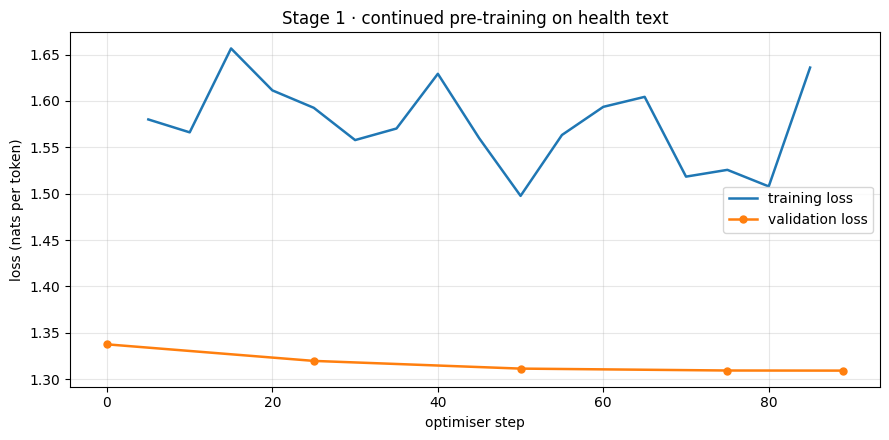

validation loss: 1.3376 -> 1.3092  (-2.1%)


In [17]:
plot_history(cpt_history,
             "Stage 1 · continued pre-training on health text",
             "loss (nats per token)",
             RESULTS / "cpt_loss.png")

**How to read this chart.** Both lines should slope downwards, with a small steady gap between
them. If the validation line flattens or turns up while training keeps falling, the model has
begun memorising — fewer steps or a lower learning rate is the fix.

If the curve looks almost **flat**, that is usually not a bug: it means few optimiser updates
relative to how much the model already knows. Check the held-out perplexity in Step 5 before
concluding nothing happened — a flat training curve can still come with a real perplexity gain.

### 3d · Stage 2 — instruction tuning (practising answers)

Stage 2 continues from the Stage 1 adapter, so the health knowledge from the reading stage is
kept. Two things change:

1. **The data.** Question/answer pairs rendered in the fixed ChatML format by
   `hl_lib.sft_tokenize`, which is the *same* renderer used at evaluation time. Training and
   evaluation must agree on the format, or Model C gets tested on something it never saw.
2. **What counts toward the loss.** Prompt tokens are labelled `-100`, which PyTorch's
   cross-entropy ignores, so the model is graded **only on the answer**. Without this it would
   waste capacity learning to predict the *question*.

In [18]:
print("tokenising the instruction data …")

sft_rows = [hl_lib.sft_tokenize(tok, r["messages"], SFT_MAX_LEN) for r in sft_train[:MAX_SFT]]
sft_val_rows = [hl_lib.sft_tokenize(tok, r["messages"], SFT_MAX_LEN) for r in sft_val[:N_VAL_SFT]]

pad_id = tok.pad_token_id if tok.pad_token_id is not None else tok.eos_token_id
collate = lambda b: hl_lib.pad_collate(b, pad_id)

sft_train_loader = DataLoader(sft_rows, batch_size=MICRO_BATCH, shuffle=True,
                              collate_fn=collate, drop_last=True)
sft_val_loader = DataLoader(sft_val_rows, batch_size=MICRO_BATCH, shuffle=False,
                            collate_fn=collate)

sft_steps = max(1, len(sft_rows) // (MICRO_BATCH * GRAD_ACCUM))

# Confirm the masking before training on thousands of these
example = sft_rows[0]
n_prompt = sum(1 for x in example["labels"] if x == -100)
print(f"\nexample 0: {len(example['input_ids'])} tokens, "
      f"{n_prompt} masked as prompt, {len(example['labels']) - n_prompt} scored as answer")
print("first tokens actually scored (should be the start of the answer):")
print("  " + repr(tok.decode([x for x in example["labels"] if x != -100][:24])))
print(f"\n{len(sft_rows):,} training examples -> {sft_steps} optimiser steps")

tokenising the instruction data …

example 0: 224 tokens, 80 masked as prompt, 144 scored as answer
first tokens actually scored (should be the start of the answer):
  'Summary : Food provides the energy and nutrients you need to be healthy. Nutrients include proteins, carbohydrates, fats, vitamins'

3,000 training examples -> 187 optimiser steps


In [19]:
ckpt = saved_adapter(ADAPTER_SFT)

if ckpt is not None and not FORCE_RETRAIN:
    print(f"found an existing Stage 2 adapter at {ADAPTER_SFT} — loading instead of retraining.")
    sft_history = load_adapter_into(model, ADAPTER_SFT)
else:
    sft_history = train_stage(model, sft_train_loader, sft_val_loader,
                              steps=sft_steps, lr=SFT_LR, tag="stage 2",
                              save_to=ADAPTER_SFT, tok=tok)
    model.save_pretrained(str(ADAPTER_SFT))
    tok.save_pretrained(str(ADAPTER_SFT))
    print(f"\nStage 2 adapter saved to {ADAPTER_SFT}")

(RESULTS / "sft_log.json").write_text(json.dumps(sft_history, indent=1))

found an existing Stage 2 adapter at /content/drive/MyDrive/NLP_LABS/health_llm/adapter_sft — loading instead of retraining.
loaded 504 adapter tensors from /content/drive/MyDrive/NLP_LABS/health_llm/adapter_sft/adapter_model.safetensors


1039

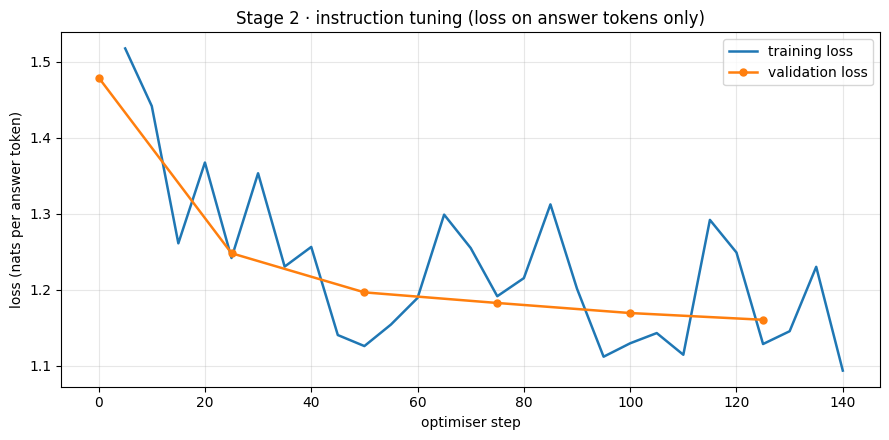

validation loss: 1.4794 -> 1.1607  (-21.5%)


In [20]:
plot_history(sft_history,
             "Stage 2 · instruction tuning (loss on answer tokens only)",
             "loss (nats per answer token)",
             RESULTS / "sft_loss.png")

In [21]:
# Free the GPU before evaluation reloads the model three times
del model
gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()
print(f"GPU memory now: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

GPU memory now: 0.00 GB


> **Draft answer (Q3 — 2 to 3 paragraphs).** Describe the two stages and the settings: QLoRA
> with r=32 and α=64 on all seven projections of every block, 4-bit NF4 base weights with
> double quantisation, 8-bit AdamW at 1e-4 on a cosine schedule with 10 warm-up steps, an
> effective batch of 16 blocks (32,768 tokens), gradient checkpointing, and fp16 with a
> gradient scaler because the T4 has no bf16. Then give the evidence: validation loss before
> versus after Stage 1, both curves falling together, the answer-only loss falling in Stage 2,
> and — from Step 5 — held-out perplexity dropping on unseen health text while WikiText-2 stays
> flat. Quote the measured steps/minute and peak GPU memory to show the run really fitted.

---

# Step 4 · Q4. How did we evaluate?

> **In plain words.** We ask three versions of the model the same questions and compare.
> **A** is the untouched original, **B** has done the reading, **C** has done the reading *and*
> the practice. Three kinds of test: (1) how *surprised* is each by health text it has never
> seen, (2) multiple-choice medical exam questions, (3) realistic patient stories we read
> ourselves. We also test on ordinary Wikipedia text, to check it did not forget general
> English while learning medicine.

### The three tests

**1 · Perplexity** — the standard intrinsic score for a language model:

$$\text{Perplexity} = \exp\left(-\frac{1}{N}\sum_i \log P_\theta(x_i \mid x_{<i})\right)$$

Read it as *"the effective number of equally likely next tokens the model is choosing
between."* Lower is better. Scores only compare when the tokenizer and the text are identical,
which is why all three models share both.

Four held-out sets: **PubMed Central**, **MedlinePlus**, **Ghana STG/EML**, and **WikiText-2**.
The first three should fall from A to B if Stage 1 worked. The fourth is the **control** — a
large rise there means catastrophic forgetting.

**2 · Zero-shot multiple choice** — MedQA, MedMCQA, PubMedQA. We append `Answer:` and compare
the next-token scores for the option letters. Nothing is generated and nothing must be parsed,
which is fast and fair to a base model. Two prompt styles (plain and chat) are scored and the
better reported, so no model is penalised for the wrong wrapper.

*Chance:* 25 % for MedQA and MedMCQA. PubMedQA is three-way (33 %), but always answering "yes"
scores about 55 %, so that is the real bar.

**3 · GP vignettes** — patient stories read side by side by a human. Plausible conditions?
Red-flag symptoms? A sensible next step? Anything dangerous invented?

All three functions come from `hl_lib.py`, unchanged — the same code the other notebooks in this
project use, so the numbers are directly comparable across runs.

In [22]:
from peft import PeftModel

mcq_items = [
    item
    for task in ("MedQA", "MedMCQA", "PubMedQA")
    for item in [x for x in mcq_all if x["task"] == task][:N_MCQ]
]
ppl_sources = sorted({d["source"] for d in heldout})

MODELS_UNDER_TEST = [
    ("A · base",         None),
    ("B · +stage 1",     ADAPTER_CPT),
    ("C · +stage 1 + 2", ADAPTER_SFT),
]

results_path = RESULTS / "eval_results.json"
results = json.loads(results_path.read_text()) if results_path.exists() else {}

print(f"{len(mcq_items)} exam questions, {len(heldout)} held-out passages, "
      f"{N_VIGNETTES} vignettes, per model")
print(f"perplexity sources: {ppl_sources}")

900 exam questions, 444 held-out passages, 12 vignettes, per model
perplexity sources: ['medlineplus', 'moh_ghana', 'pmc_oa', 'wikitext2']


In [23]:
for label, adapter in MODELS_UNDER_TEST:
    if label in results:
        print(f"{label}: already scored, skipping")
        continue

    print(f"\n{'=' * 70}\n{label}\n{'=' * 70}")
    started = time.time()

    m = load_base(for_training=False)
    if adapter is not None:
        m = PeftModel.from_pretrained(m, str(adapter))
    m.eval()

    entry = {"perplexity": {}}

    for source in ppl_sources:
        texts = [d["text"] for d in heldout if d["source"] == source]
        entry["perplexity"][source] = hl_lib.perplexity(m, tok, texts, max_len=PPL_MAX_LEN)
        print(f"  perplexity · {source:<14}{entry['perplexity'][source]:>9.2f}")

    entry["mcq_plain"] = hl_lib.mcq_accuracy(m, tok, mcq_items, "plain")
    entry["mcq_chat"] = hl_lib.mcq_accuracy(m, tok, mcq_items, "chat")
    for task in entry["mcq_plain"]:
        print(f"  accuracy   · {task:<14}"
              f"plain {entry['mcq_plain'][task]:.3f} | chat {entry['mcq_chat'][task]:.3f}")

    entry["generations"] = [
        hl_lib.generate(m, tok, v["prompt"], mode="chat" if label.startswith("C") else "plain")
        for v in vignettes[:N_VIGNETTES]
    ]

    results[label] = entry
    results_path.write_text(json.dumps(results, indent=1))
    print(f"  done in {(time.time() - started) / 60:.1f} min")

    del m
    gc.collect()
    torch.cuda.empty_cache()

print(f"\nall results saved to {results_path}")


A · base


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

  perplexity · medlineplus        4.12
  perplexity · moh_ghana          6.59
  perplexity · pmc_oa             5.15
  perplexity · wikitext2          9.66
  accuracy   · MedQA         plain 0.593 | chat 0.593
  accuracy   · MedMCQA       plain 0.583 | chat 0.513
  accuracy   · PubMedQA      plain 0.700 | chat 0.640
  done in 14.7 min

B · +stage 1


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

  perplexity · medlineplus        4.06
  perplexity · moh_ghana          5.99
  perplexity · pmc_oa             4.54
  perplexity · wikitext2          9.50
  accuracy   · MedQA         plain 0.603 | chat 0.593
  accuracy   · MedMCQA       plain 0.580 | chat 0.513
  accuracy   · PubMedQA      plain 0.727 | chat 0.650
  done in 19.6 min

C · +stage 1 + 2


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

  perplexity · medlineplus        4.07
  perplexity · moh_ghana          6.20
  perplexity · pmc_oa             4.58
  perplexity · wikitext2          9.51
  accuracy   · MedQA         plain 0.580 | chat 0.587
  accuracy   · MedMCQA       plain 0.590 | chat 0.570
  accuracy   · PubMedQA      plain 0.760 | chat 0.740
  done in 20.2 min

all results saved to /content/drive/MyDrive/NLP_LABS/health_llm/results/eval_results.json


> **Draft answer (Q4 — 1 to 2 paragraphs).** We compared three models on identical held-out
> data: the untouched base (A), base plus Stage 1 (B), and base plus both stages (C). The
> intrinsic evaluation was perplexity on held-out PubMed Central, MedlinePlus and Ghana STG/EML
> passages, with WikiText-2 as a forgetting control. The extrinsic evaluation was zero-shot
> multiple-choice accuracy on MedQA, MedMCQA and PubMedQA, scored by comparing the next-token
> scores of the option letters and reporting the better of two prompt formats, plus a hand-read
> comparison of answers to GP vignettes. Held-out data was separated before training, and the
> multiple-choice evaluation uses the *test/validation* splits of datasets whose *train* splits
> were used in Stage 2.

---

# Step 5 · Q5. What results did we get?

Everything below is computed from *your* run. Nothing is hard-coded, and nothing should go into
the report until these cells have produced numbers.

### Reading the numbers honestly

**The margin of error matters.** With `N` questions and accuracy `p`, the 95 % margin is about
`1.96 × √(p(1−p)/N)`. The cell below prints it for your actual `N`. A difference smaller than
that is **not** a result.

**A modest gain is a legitimate finding.** The base model has already read a great deal of
biomedical text. If two stages move exam accuracy only slightly, say so plainly rather than
overclaiming — an honest null result is worth more marks than a stretched one.

In [24]:
def best_accuracy(label, task):
    """Each model is credited with the better of its two prompt formats."""
    return max(results[label]["mcq_plain"][task], results[label]["mcq_chat"][task])


labels = [l for l, _ in MODELS_UNDER_TEST if l in results]
tasks = ["MedQA", "MedMCQA", "PubMedQA"]

print("TABLE 1 · Held-out perplexity (lower is better)\n")
head = f"{'model':<20}" + "".join(f"{s:>15}" for s in ppl_sources)
print(head + "\n" + "-" * len(head))
for l in labels:
    print(f"{l:<20}" + "".join(f"{results[l]['perplexity'][s]:>15.2f}" for s in ppl_sources))

print(f"\n\nTABLE 2 · Zero-shot accuracy, N = {N_MCQ} per task (higher is better)\n")
head = f"{'model':<20}" + "".join(f"{t:>14}" for t in tasks)
print(head + "\n" + "-" * len(head))
print(f"{'chance / majority':<20}{'25.0%':>14}{'25.0%':>14}{'~55.0%':>14}")
for l in labels:
    print(f"{l:<20}" + "".join(f"{100 * best_accuracy(l, t):>13.1f}%" for t in tasks))

margin = 1.96 * math.sqrt(0.25 / N_MCQ) * 100
print(f"\n95% margin of error at p=0.5, N={N_MCQ}: ±{margin:.1f} points")
print("Differences smaller than this must NOT be reported as improvements.")

TABLE 1 · Held-out perplexity (lower is better)

model                   medlineplus      moh_ghana         pmc_oa      wikitext2
--------------------------------------------------------------------------------
A · base                       4.12           6.59           5.15           9.66
B · +stage 1                   4.06           5.99           4.54           9.50
C · +stage 1 + 2               4.07           6.20           4.58           9.51


TABLE 2 · Zero-shot accuracy, N = 300 per task (higher is better)

model                        MedQA       MedMCQA      PubMedQA
--------------------------------------------------------------
chance / majority            25.0%         25.0%        ~55.0%
A · base                     59.3%         58.3%         70.0%
B · +stage 1                 60.3%         58.0%         72.7%
C · +stage 1 + 2             58.7%         59.0%         76.0%

95% margin of error at p=0.5, N=300: ±5.7 points
Differences smaller than this must NOT be reporte

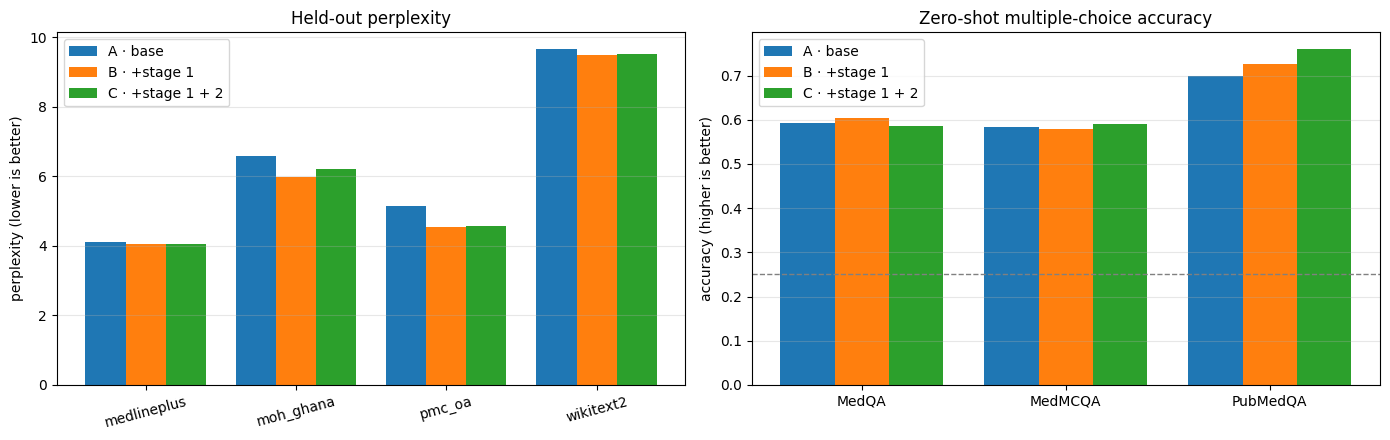

In [25]:
import numpy as np

fig, (ax_ppl, ax_acc) = plt.subplots(1, 2, figsize=(14, 4.5))
width = 0.8 / max(len(labels), 1)

for i, l in enumerate(labels):
    ax_ppl.bar(np.arange(len(ppl_sources)) + i * width,
               [results[l]["perplexity"][s] for s in ppl_sources], width, label=l)
ax_ppl.set_xticks(np.arange(len(ppl_sources)) + width)
ax_ppl.set_xticklabels(ppl_sources, rotation=15)
ax_ppl.set_ylabel("perplexity (lower is better)")
ax_ppl.set_title("Held-out perplexity")
ax_ppl.legend()
ax_ppl.grid(axis="y", alpha=0.3)

for i, l in enumerate(labels):
    ax_acc.bar(np.arange(len(tasks)) + i * width,
               [best_accuracy(l, t) for t in tasks], width, label=l)
ax_acc.axhline(0.25, linestyle="--", linewidth=1, color="grey")
ax_acc.set_xticks(np.arange(len(tasks)) + width)
ax_acc.set_xticklabels(tasks)
ax_acc.set_ylabel("accuracy (higher is better)")
ax_acc.set_title("Zero-shot multiple-choice accuracy")
ax_acc.legend()
ax_acc.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig(RESULTS / "eval_summary.png", dpi=150)
plt.show()

In [26]:
# ── The sentences for your Q5 paragraph ───────────────────────────────────────
if len(labels) >= 2:
    a, b = labels[0], labels[1]
    print("PERPLEXITY — effect of Stage 1 (A -> B)\n")
    for s in ppl_sources:
        before, after = results[a]["perplexity"][s], results[b]["perplexity"][s]
        tag = "   <- general-English control" if s == "wikitext2" else ""
        print(f"  {s:<14}{before:>9.2f} -> {after:>9.2f}   {100 * (after / before - 1):+6.1f}%{tag}")

if len(labels) >= 3:
    print("\n\nACCURACY — all three models\n")
    for t in tasks:
        print(f"  {t:<12}" + "  ->  ".join(f"{100 * best_accuracy(l, t):.1f}%" for l in labels))
    print(f"\n  (±{margin:.1f} points is noise at N={N_MCQ})")

PERPLEXITY — effect of Stage 1 (A -> B)

  medlineplus        4.12 ->      4.06     -1.6%
  moh_ghana          6.59 ->      5.99     -9.1%
  pmc_oa             5.15 ->      4.54    -11.9%
  wikitext2          9.66 ->      9.50     -1.7%   <- general-English control


ACCURACY — all three models

  MedQA       59.3%  ->  60.3%  ->  58.7%
  MedMCQA     58.3%  ->  58.0%  ->  59.0%
  PubMedQA    70.0%  ->  72.7%  ->  76.0%

  (±5.7 points is noise at N=300)


### The GP vignettes, side by side

**Read these yourself — this is the qualitative half of the evaluation.** For each case ask:

- Does it name a **plausible condition**?
- Does it mention **red-flag symptoms** needing urgent care?
- Does it suggest a **sensible next step**?
- Does it invent anything **unsafe** — a drug, a dose, a diagnosis?

Watch especially the difference between A and C. A base model tends to *continue* the prompt;
an instruction-tuned one tends to *answer* it in a structured way. Record your judgements in
the scoring sheet in Appendix C of the report.

In [28]:
for i, v in enumerate(vignettes[:N_VIGNETTES]):
    print("=" * 100)
    print(f"VIGNETTE {i + 1}")
    print("=" * 100)
    print(f"PATIENT: {v['prompt']}\n")
    for l in labels:
        print(f"  ── {l} ──")
        print(f"  {results[l]['generations'][i].replace(chr(10), ' ')[:700]}\n")

VIGNETTE 1
PATIENT: A 4-year-old child in a rural village in Northern Ghana has had fever for 3 days with chills, vomiting and refuses to eat. He is very sleepy today. What could be going on and what should be done?

  ── A · base ──
  The child may have malaria. Malaria is the most common cause of fever in children under five years old in sub-Saharan Africa. It is caused by Plasmodium parasites that are transmitted through the bite of infected Anopheles mosquitoes. Symptoms include fever, headache, muscle pain, nausea, vomiting, diarrhea, and anemia. In severe cases, it can lead to seizures, coma, and death. To diagnose malaria, a blood smear should be taken from the child's finger or earlobe and examined under a microscope for the presence of parasites. If malaria is confirmed, treatment should be started immediately with antimalarial drugs such as artemisinin-based combination therapy (ACT). Other supportive measures su

  ── B · +stage 1 ──
  The child may have malaria. Malaria is 

> **How to write the answer (Q5 — 1 to 2 paragraphs).** Use the printed numbers, not
> impressions. Say whether perplexity fell on the three health sets and by how much, and what
> happened on WikiText-2 (roughly flat means no catastrophic forgetting). Report accuracy for
> A, B and C against chance, and state the margin of error before calling any difference real.
> Add one sentence from the vignettes. A 4 B model will not match large medical models on
> MedQA; do not imply that it does.

---

# Step 6 · Q6. What else should we know?

> **In plain words.** This is a **school exercise, not a doctor.** It can be confidently wrong,
> which is more dangerous than being obviously wrong. Never use it for a real medical decision.

### Limitations

- **Not a clinical tool.** No clinician validated any output. Exam accuracy measures exam
  knowledge, not consultation quality, and the vignette judgements are subjective.
- **A small, single run.** One seed, one pass, a modest token budget. Differences of a point or
  two are inside run-to-run noise.
- **Compute shaped the scope.** We train on a fraction of the available tokens. More tokens, or
  a larger model, is the obvious next step.
- **The base model has seen medicine before.** Much biomedical text is in any modern model's
  pre-training data, so attributable gains may be modest. That is a finding, not a failure.
- **Benchmark leakage cannot be ruled out.** We never trained on the test splits, but the base
  model's original web-scale pre-training may have included public benchmark text.
- **Quantisation costs a little accuracy.** The frozen weights are 4-bit. What we *learn* stays
  full precision, but Model A is being scored in 4-bit too — so the comparison is fair, while
  the absolute numbers would be slightly better in 16-bit.
- **English only, and skewed.** PubMed over-represents research-country populations. Conditions
  and drug availability common in rural Ghana may be under-represented, and no Ghanaian
  language is covered. Nothing here measures fairness across groups.
- **Guidelines age.** The Ghana STG/EML used here is the 2017 edition; a newer edition
  supersedes it. Record the edition and year whenever you cite it.

### Ethics

- **Hallucination and over-confidence.** A small model can invent a drug dose in fluent,
  authoritative prose. Fluency is not accuracy.
- **Privacy.** We deliberately avoided datasets scraped from patient–doctor chat sites.
- **Equity.** Whose health data is represented shapes who the model serves well.
- **Transparency and accountability.** It must be obvious to any user that this is a program
  and not a clinician, and a human professional must stay in the loop.

**What we did:** licensed, non-personal data with the licence recorded per document; an explicit
"general information, not a substitute for a clinician" system prompt; evaluation on data
separated before training; honest reporting of the limits above.

**What we would add:** clinician review, hard-coded red-flag rules that override the model,
alignment training (RLHF or DPO) for safe refusals, and retrieval with citations.

> **Draft answer (Q6 — 1 to 3 paragraphs).** Pick the three that matter most. The strongest are
> the not-a-clinical-tool caveat, the small single run, and the honest statement that the base
> model already knew a lot of medicine so the attributable gain is modest.

---

## Reproducing this work

```
collect.py  →  prep.py  →  this notebook
```

| Path | What it is |
|:--|:--|
| `adapter_cpt/` | Stage 1 adapter (Model B) |
| `adapter_sft/` | Stage 1 + 2 adapter (Model C) |
| `results/cpt_log.json`, `results/sft_log.json` | Loss curves as raw numbers |
| `results/cpt_loss.png`, `results/sft_loss.png` | Figures 3 and 4 for the report |
| `results/eval_results.json` | Every number in Step 5 |
| `results/eval_summary.png` | Figure 5 for the report |

The base model is never modified, so **Model A is exactly recoverable** by loading `MODEL` with
no adapter. Everything else rebuilds from the base download plus two small adapter files.